# Tutorial: Benchmarking Repeated Auctions with `dynamicauc`


Welcome to the **DynamicAuc** tutorial.

This notebook will guide you through:
1. Defining Scenarios  
2. Using the Gymnasium API  
3. Running Simulators  


## 1. Setup and Imports

In [1]:

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dynamicauc as dac

plt.style.use('seaborn-v0_8-whitegrid')


## 2. Creating Scenarios

In [2]:

print("Available presets:", dac.list_scenarios())
print(dac.describe_scenarios())

scenario = dac.make("saturation-first-price-uniform")

info = dac.get_scenario_info("saturation-first-price-uniform")
print(f"\nScenario Description: {info['description']}")


Available presets: ['saturation-first-price-uniform', 'recency-second-price-lognormal', 'mixed-first-price-exponential']
Available Scenarios

saturation-first-price-uniform
  Saturation kernel with first-price auction and uniform competition

recency-second-price-lognormal
  Recency kernel with second-price auction and lognormal competition

mixed-first-price-exponential
  Mixed kernel (immediate + delayed) with first-price and exponential competition

Scenario Description: Saturation kernel with first-price auction and uniform competition


In [3]:

scenario_custom = (
    dac.ScenarioBuilder()
    .with_kernel("saturation", base_rate=0.5, saturation_scale=10.0)
    .with_auction("first-price")
    .with_competition("uniform", low=0.0, high=20.0)
    .with_arrival("poisson", breakpoints=[5.0], intensities=[0.1, 1.2])
    .with_display("iid", dim=3)
    .with_horizon(10.0)
    .with_user_features([0.5, 0.8, 0.02])
    .build()
)


In [4]:

scenario_high_sat = dac.make(
    "saturation-first-price-uniform",
    horizon=20.0,
    kernel_saturation_scale=50.0
)


### **Note on Parameter Overrides**
The `make` function uses a **flattened prefix convention** to modify nested parameters. Instead of passing complex dictionaries, use the `prefix_parameter` syntax.

The factory logic splits keys at the first underscore to surgically update a primitive's `params` without overwriting the entire component (like the model type or distribution name).

---

### **Quick Usage Reference**
* **Top-level:** `horizon=20.0`, `user_features=[...]`
* **Nested:** `[component]_[parameter]=[value]`

| Target Component | flattened Key Example | Maps to Preset Path |
| :--- | :--- | :--- |
| **Kernel** | `kernel_saturation_scale=5.0` | `kernel['params']['saturation_scale']` |
| **Competition** | `competition_low=0.1` | `competition['params']['low']` |
| **Arrival** | `arrival_intensities=[1.5]` | `arrival['params']['intensities']` |

**Example:**

In [23]:
scenario_smaller_bound = dac.make("saturation-first-price-uniform", competition_high=0.2, kernel_saturation_scale=40.0, 
                                  kernel_delay_rate=0.1, horizon=500.0, kernel_base_rate=0.9) 
print(f"scenario_smaller_bound competition params: {scenario_smaller_bound.competition.high}, {scenario_smaller_bound.competition.low}")
print(f"scenario_smaller_bound kernel params: {scenario_smaller_bound.kernel.saturation_scale}, {scenario_smaller_bound.kernel.delay_rate}")

scenario_smaller_bound competition params: 0.2, 0.0
scenario_smaller_bound kernel params: 40.0, 0.1


## 3. Gym Integration

In [27]:

env = gym.make("DynamicAuction-v0", scenario=scenario_smaller_bound, stochastic_reward=True)

obs, info = env.reset(seed=42)
history = []

total_reward = 0.0
terminated = False
truncated = False

while not (terminated or truncated):
    bid = scenario.policy.bid(
        u=obs["user_features"],
        x=obs["display_features"],
        ctx=obs["ctx"].item(),
        y_func=env.unwrapped.state.y_func,
        t=obs["t"].item(),
        scenario=scenario,
    )
    expected_value = env.unwrapped.kernel.expected_reward(
        u=obs["user_features"],
        x=obs["display_features"],
        ctx=obs["ctx"].item(),
        y_func=env.unwrapped.state.y_func,
        t=obs["t"].item(),
        horizon=scenario.horizon
    )
    
    obs, reward, terminated, truncated, info = env.step(bid)
    
    history.append({
            "time": obs['t'].item(),
            "context": obs["ctx"].item(),
            "expected_value": expected_value,
            "won": info["auction"]["won"],
            "reward": reward
        })

    current_t = obs['t'].item()
    comp_bid = info["auction"]["competing_bid"]
    
    print(f"t={current_t:.2f} | Bid: {bid:.2f} | Compete: {comp_bid:.2f} | Reward: {reward:.4f}")
    
    total_reward += reward
print(f"Episode Finished. Total Reward: {total_reward:.2f}")
env.close()


t=7.69 | Bid: 0.22 | Compete: 0.15 | Reward: 0.7826
t=8.62 | Bid: 0.09 | Compete: 0.02 | Reward: 0.9066
t=8.64 | Bid: 0.05 | Compete: 0.05 | Reward: 0.9473
t=10.31 | Bid: 0.05 | Compete: 0.09 | Reward: 0.0000
t=11.09 | Bid: 0.00 | Compete: 0.19 | Reward: 0.0000
t=11.90 | Bid: 0.00 | Compete: 0.05 | Reward: 0.0000
t=12.27 | Bid: 0.00 | Compete: 0.18 | Reward: 0.0000
t=13.83 | Bid: 0.00 | Compete: 0.01 | Reward: 0.0000
t=15.47 | Bid: 0.00 | Compete: 0.02 | Reward: 0.0000
t=15.70 | Bid: 0.00 | Compete: 0.03 | Reward: 0.0000
t=16.24 | Bid: 0.00 | Compete: 0.12 | Reward: 0.0000
t=16.29 | Bid: 0.00 | Compete: 0.08 | Reward: 0.0000
t=17.29 | Bid: 0.00 | Compete: 0.19 | Reward: 0.0000
t=17.31 | Bid: 0.00 | Compete: 0.05 | Reward: 0.0000
t=19.35 | Bid: 0.00 | Compete: 0.09 | Reward: 0.0000
t=20.25 | Bid: 0.00 | Compete: 0.17 | Reward: 0.0000
t=22.85 | Bid: 0.00 | Compete: 0.05 | Reward: 0.0000
t=22.90 | Bid: 0.00 | Compete: 0.16 | Reward: 0.0000
t=23.52 | Bid: 0.00 | Compete: 0.11 | Reward: 0.0

## 4. Visualization

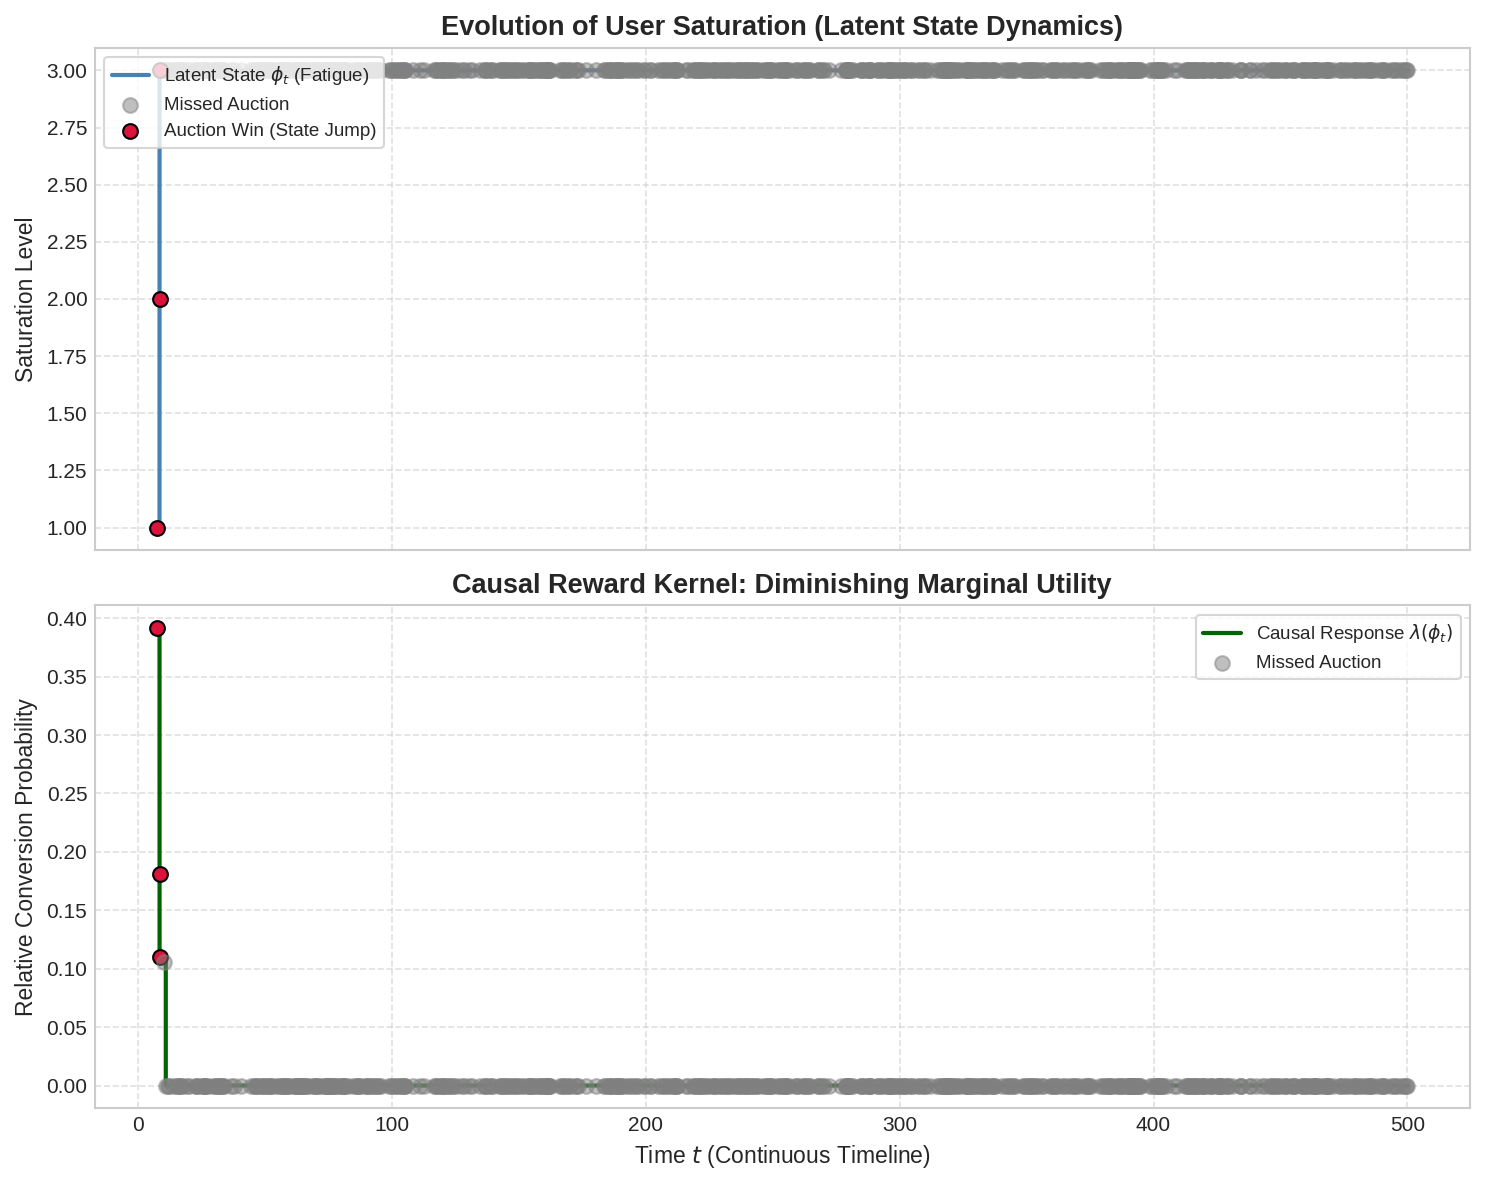

In [28]:
def plot_value_dynamics(history):
    df = pd.DataFrame(history)
    wins = df[df['won']]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, dpi=150)
    
    ax1.step(df['time'], df['context'], where='post', color='steelblue', 
             linewidth=2, label=r'Latent State $\phi_t$ (Fatigue)')
    
    ax1.scatter(df[~df['won']]['time'], df[~df['won']]['context'], 
                color='gray', alpha=0.5, s=50, label='Missed Auction', zorder=3)
    ax1.scatter(wins['time'], wins['context'], color='crimson', 
                edgecolor='black', s=50, label='Auction Win (State Jump)', zorder=3)
    
    ax1.set_ylabel("Saturation Level", fontsize=11)
    ax1.set_title("Evolution of User Saturation (Latent State Dynamics)", fontsize=13, weight='bold')
    ax1.legend(frameon=True, loc='upper left', fontsize=9)
    ax1.grid(True, linestyle='--', alpha=0.6)
    
    # --- PANEL 2: The Reward Kernel (Causal Response) ---
    ax2.step(df['time'], df['expected_value'], where='post', color='darkgreen', 
             linewidth=2, label=r'Causal Response $\lambda(\phi_t)$')
    
    ax2.scatter(wins['time'], wins['expected_value'], color='crimson', 
                edgecolor='black', s=50, zorder=3)
    ax2.scatter(df[~df['won']]['time'], df[~df['won']]['expected_value'], 
                color='gray', alpha=0.5, s=50, label='Missed Auction', zorder=3)
    
    ax2.set_xlabel(r"Time $t$ (Continuous Timeline)", fontsize=11)
    ax2.set_ylabel("Relative Conversion Probability", fontsize=11)
    ax2.set_title("Causal Reward Kernel: Diminishing Marginal Utility", fontsize=13, weight='bold')
    ax2.legend(frameon=True, loc='upper right', fontsize=9)
    ax2.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

plot_value_dynamics(history)

## 5. Simulator

In [ ]:

from dynamicauc.simulator import Simulator

sim = Simulator(scenario, campaign_cfg={
    "horizon": 10.0,
    "n_runs": 100,
    "seed": 42,
})

auctions_df, displays_df, conversions_df, summary_df = sim.run()

print(f"Average Win Rate: {summary_df['win_rate'].mean():.2%}")
print(f"Mean Conversions per Campaign: {summary_df['n_conversions'].mean():.2f}")
